Hospital Data Analysis

In [208]:
import pandas as pd
from matplotlib import pyplot as plt

Task 1 – Monthly Patient Admission Trend

In [209]:
df = pd.read_excel("Hospital_Matplotlib_Analysis_30_Records.xlsx")
df.head()

,Patient_ID,Admission_Date,Department,City,Gender,Age,Visit_Type,Ward_Type,Treatment_Cost,Length_of_Stay_Days,Waiting_Time_Min,Number_of_Tests,Readmission_30_Days
0,2001,2026-01-03,Cardiology,Pune,Male,62,Emergency,General Ward,4200,3,85,2,1
1,2002,2026-01-05,Orthopedics,Pune,Female,45,OPD,General Ward,2800,2,35,1,0
2,2003,2026-01-07,Neurology,Mumbai,Male,58,Emergency,ICU,12500,7,110,4,1
3,2004,2026-01-10,Pediatrics,Pune,Female,8,OPD,General Ward,1800,1,25,0,0
4,2005,2026-01-12,General Medicine,Nashik,Male,51,OPD,General Ward,2200,2,40,1,0


In [210]:
# Extract the month number from Admission_Date
df["Month"] = df["Admission_Date"].dt.month
print(df[["Admission_Date", "Month"]])

   Admission_Date  Month
0      2026-01-03      1
1      2026-01-05      1
2      2026-01-07      1
3      2026-01-10      1
4      2026-01-12      1
5      2026-01-15      1
6      2026-01-18      1
7      2026-01-21      1
8      2026-01-24      1
9      2026-01-27      1
10     2026-02-02      2
11     2026-02-05      2
12     2026-02-08      2
13     2026-02-11      2
14     2026-02-14      2
15     2026-02-18      2
16     2026-02-21      2
17     2026-02-24      2
18     2026-02-26      2
19     2026-02-28      2
20     2026-03-03      3
21     2026-03-06      3
22     2026-03-09      3
23     2026-03-12      3
24     2026-03-15      3
25     2026-03-18      3
26     2026-03-21      3
27     2026-03-24      3
28     2026-03-27      3
29     2026-03-30      3


In [211]:
# Count the number of patients admitted in each month
monthly_admission = df.groupby("Month")["Patient_ID"].count()
print(monthly_admission)

Month
1    10
2    10
3    10
Name: Patient_ID, dtype: int64


In [212]:
# Convert month numbers into month names
monthly_admission.index = monthly_admission.index.map({
    1: "January",
    2: "February",
    3: "March"
})

print(monthly_admission)

Month
January     10
February    10
March       10
Name: Patient_ID, dtype: int64


In [213]:
# Short name have like (Jan, Feb...) so string slice 
# df["Month"] = df["Admission_Date"].dt.month_name().str[:3]
# df

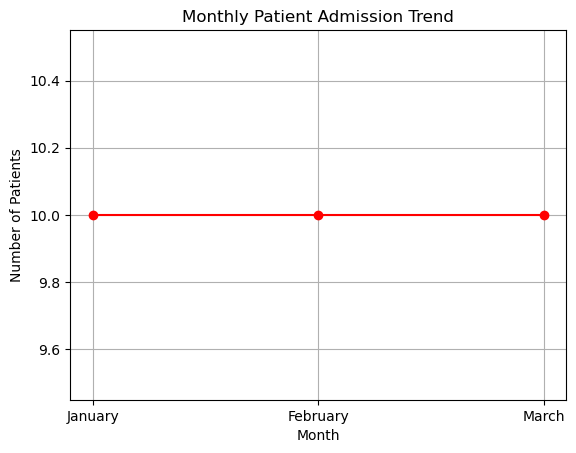

In [214]:
# Create a line chart for monthly patient admissions
plt.plot(
    monthly_admission.index,
    monthly_admission.values,
    marker="o",
    color = 'red'
  
)

# Add a title to the chart
plt.title("Monthly Patient Admission Trend")

# Label the X-axis
plt.xlabel("Month")

# Label the Y-axis
plt.ylabel("Number of Patients")

# Display grid lines
plt.grid(True)

# Display the chart
plt.show()

Business Insights:
1. Patient admissions remained constant at 10 patients per month during January, February, and March.

2. No significant increase or decrease in patient demand is observed during the analyzed period.

3. The hospital may maintain relatively stable staffing and resource allocation because the monthly patient volume is consistent.

Task 2 – Department-wise Patient Volume

In [215]:
# Count the number of patients in each department
department_patient_count = df.groupby("Department")["Patient_ID"].count()
print(department_patient_count)

Department
Cardiology          6
General Medicine    6
Neurology           6
Orthopedics         6
Pediatrics          6
Name: Patient_ID, dtype: int64


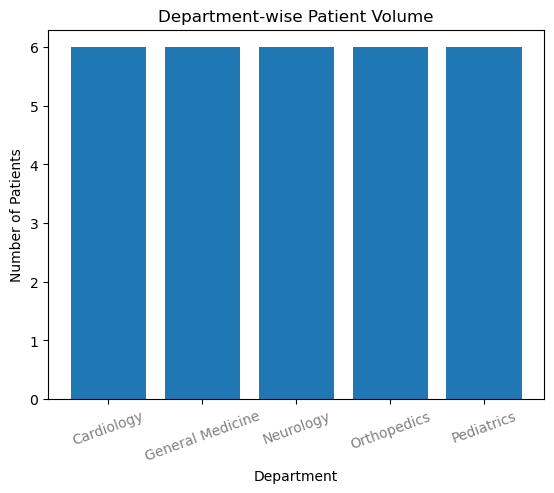

In [216]:
# Create a bar chart for department-wise patient volume
plt.bar(
    department_patient_count.index,
    department_patient_count.values
)

# Add a title to the chart
plt.title("Department-wise Patient Volume")

# Label the X-axis
plt.xlabel("Department")

# Label the Y-axis
plt.ylabel("Number of Patients")

# Rotate department names for better readability
plt.xticks(rotation=20, ha = 'center',color = 'grey')

 
plt.show()

Business Insight:
1. All four departments have an equal patient volume of 6 patients each.
2. No single department has a higher or lower patient workload compared with the other departments.
3. The hospital may maintain a balanced allocation of staff and resources across these departments.

Task 3 – Department-wise Treatment Cost

In [217]:
 # Calculate the total treatment cost for each department
department_treatment_cost = df.groupby("Department")["Treatment_Cost"].sum()

# Sort the treatment cost from highest to lowest
department_treatment_cost = department_treatment_cost.sort_values(ascending=False)

print(department_treatment_cost)


Department
Neurology           76000
Cardiology          73800
Orthopedics         24600
General Medicine    20900
Pediatrics          11850
Name: Treatment_Cost, dtype: int64


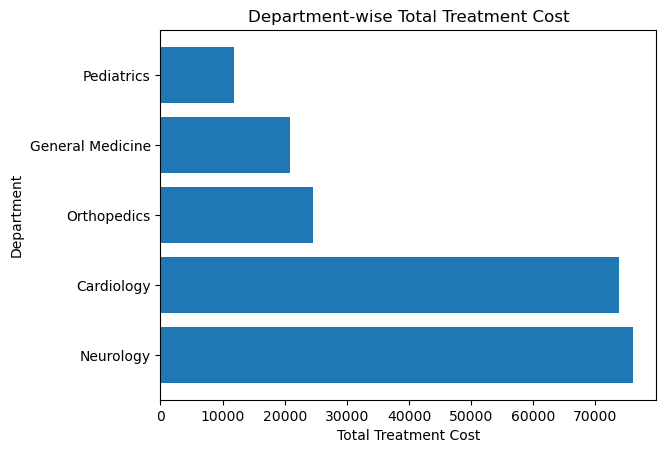

In [218]:
# Create a horizontal bar chart
plt.barh(
    department_treatment_cost.index,
    department_treatment_cost.values
)

# Add a title to the chart
plt.title("Department-wise Total Treatment Cost")

# Label the X-axis
plt.xlabel("Total Treatment Cost")

# Label the Y-axis
plt.ylabel("Department")
 
plt.show()

Business Insights:

1. "Neurology generates the highest revenue"

2. Neurology has the highest total treatment cost of ₹76,000 among all departments.

3. Pediatrics has the lowest total treatment cost of ₹11,850.

4. Neurology and Cardiology may require closer financial monitoring because their total treatment costs are significantly higher than the other departments.

Task 4 – OPD vs Emergency Analysis

In [219]:
# Count the number of patients for each visit type
visit_type_count = df["Visit_Type"].value_counts()
 
print(visit_type_count)
visit_type_count.sum()

Visit_Type
OPD          16
Emergency    14
Name: count, dtype: int64


np.int64(30)

In [220]:
# Calculate the percentage of each visit type
visit_type_percentage = visit_type_count / visit_type_count.sum() * 100

# Display the percentage
print(visit_type_percentage)

Visit_Type
OPD          53.333333
Emergency    46.666667
Name: count, dtype: float64


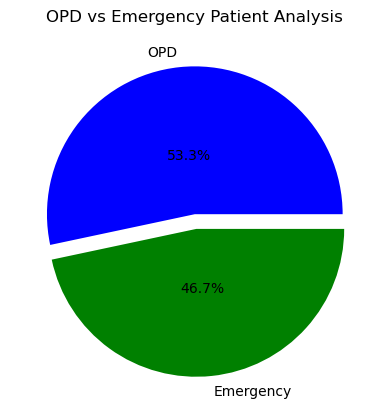

In [221]:
# Create a pie chart showing the patient mix
plt.pie(
    visit_type_count.values,
    labels=visit_type_count.index,
    autopct="%1.1f%%",
    explode=[0,0.1],
    colors=['blue','green'],
    radius= 1.0,
    pctdistance= 0.4
     
)

# Add a title to the chart
plt.title("OPD vs Emergency Patient Analysis")
 
plt.show()

Business Insights:

1. OPD cases account for 53.33% of the total patient volume, making them slightly higher than Emergency cases.
2. Emergency cases account for 46.67% of the total patient volume, indicating a significant Emergency workload.
3. The patient mix is relatively balanced between OPD and Emergency visits, so hospital management should monitor Emergency capacity and resource requirements.

Task 5 – Waiting Time vs Treatment Cost

In [222]:
# Display waiting time and treatment cost for each patient
df.head()[["Patient_ID", "Waiting_Time_Min", "Treatment_Cost"]]

,Patient_ID,Waiting_Time_Min,Treatment_Cost
0,2001,85,4200
1,2002,35,2800
2,2003,110,12500
3,2004,25,1800
4,2005,40,2200


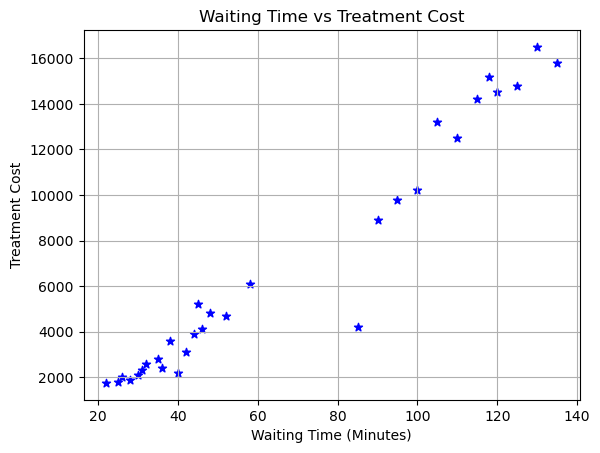

In [223]:
# Create a scatter plot to compare waiting time and treatment cost
plt.scatter(
    df["Waiting_Time_Min"],
    df["Treatment_Cost"],
    marker= '*',
    color= 'blue',
    
)

# Add a title to the chart
plt.title("Waiting Time vs Treatment Cost")

# Label the X-axis
plt.xlabel("Waiting Time (Minutes)")

# Label the Y-axis
plt.ylabel("Treatment Cost")

# Display grid lines
plt.grid(True)
 
plt.show()

In [224]:
corr = df['Waiting_Time_Min'].corr(df['Treatment_Cost'])
print("Correlation:", round(corr, 2))

Correlation: 0.97


Analysis: There is a very strong positive relationship between waiting time and treatment cost (correlation ≈ 0.97). Low-cost patients (OPD/Pediatrics) wait 22–58 minutes, while high-cost patients (Emergency/ICU) wait 90–135 minutes.

Business Insights:
1. Expensive cases wait longer: Costly cases (₹12,000–16,500) generally wait 100–135 minutes because they are more serious and complex.
2. Unusually high waiting times: Emergency/ICU patients in Cardiology and Neurology wait 115–135 minutes. The triage and ICU admission processes should be reviewed.
3. High-cost patients with low waiting time: None. No expensive case was seen quickly. One outlier is Patient 2001 (Cardiology, Emergency), who waited 85 minutes but had a cost of only ₹4,200, and this case should be reviewed.

Task 6 – Monthly Average Waiting Time

In [225]:
# Extract the month number from Admission_Date
df["Month"] = df["Admission_Date"].dt.month

# Calculate the average waiting time for each month
monthly_waiting_time = df.groupby("Month")["Waiting_Time_Min"].mean()

# Convert month numbers into month names
monthly_waiting_time.index = monthly_waiting_time.index.map({
    1: "January",
    2: "February",
    3: "March"
})
 
print(monthly_waiting_time)

Month
January     63.8
February    66.8
March       70.0
Name: Waiting_Time_Min, dtype: float64


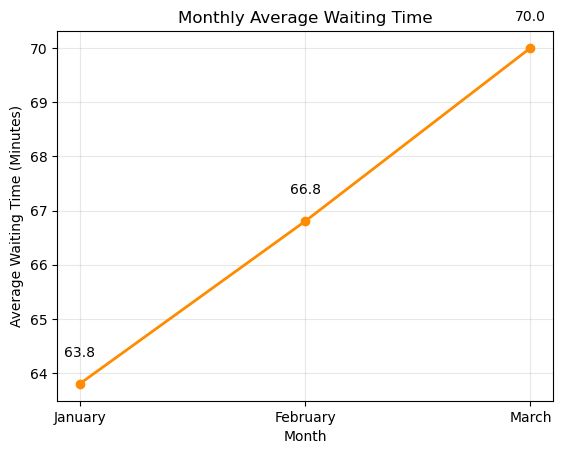

In [226]:
# Create a line chart for monthly average waiting time
plt.plot(
    monthly_waiting_time.index,
    monthly_waiting_time.values,
     marker='o', color='darkorange', linewidth=2
)

# Show the value on each point
for i, v in enumerate(monthly_waiting_time.values):
    plt.text(i, v + 0.5, f'{v:.1f}', ha='center')
    
# Add a title to the chart
plt.title("Monthly Average Waiting Time")

# Label the X-axis
plt.xlabel("Month")

# Label the Y-axis
plt.ylabel("Average Waiting Time (Minutes)")

# Display grid lines
plt.grid(alpha= 0.3)
 
plt.show()

Analysis: Average waiting time has increased steadily every month, from 63.8 minutes in January to 66.8 minutes in February and 70.0 minutes in March.

Business Insights:
1. Highest and lowest: March has the highest average waiting time (70.0 minutes) and January has the lowest (63.8 minutes).
2. Waiting time is worsening: It rose by about 6 minutes (around 10%) over three months, so operational efficiency is not improving.
3. Possible cause: The share of Emergency cases went up from 4 in January to 5 in February and March. Emergency cases have much longer waits, so even a small rise pushes the average up. Management should review triage and staffing, especially for Emergency patients.

Task 7 – Department-wise Average Length of Stay

In [227]:
# Calculate the average length of stay for each department
department_avg_stay = df.groupby("Department")["Length_of_Stay_Days"].mean()

# Sort departments by average length of stay from highest to lowest
department_avg_stay = department_avg_stay.sort_values(ascending=False)
 
print(department_avg_stay)

Department
Cardiology          6.666667
Neurology           6.666667
Orthopedics         2.666667
General Medicine    2.500000
Pediatrics          1.000000
Name: Length_of_Stay_Days, dtype: float64


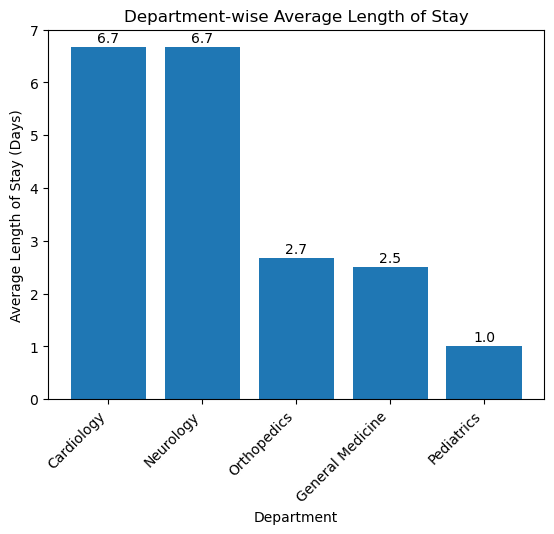

In [228]:
# Create a bar chart for department-wise average length of stay
plt.bar(
    department_avg_stay.index,
    department_avg_stay.values
)
# Show the value on each bar
for i, v in enumerate(department_avg_stay.values):
    plt.text(i, v + 0.1, f'{v:.1f}', ha='center')

# Add a title to the chart
plt.title("Department-wise Average Length of Stay")

# Label the X-axis
plt.xlabel("Department")

# Label the Y-axis
plt.ylabel("Average Length of Stay (Days)")

# Rotate department names for better readability
plt.xticks(rotation=45, ha='right')

# Display the chart
plt.show()

Analysis: Cardiology and Neurology have the longest average stay (6.67 days each), while Pediatrics has the shortest (1.0 day). Orthopedics (2.67 days) and General Medicine (2.5 days) are in the middle.

Business Insights:
1. Longest stay: Cardiology and Neurology patients stay about 6.7 days on average, which is more than double the other departments. These two departments use the most bed days.
2. Shortest stay: Pediatrics patients stay only 1 day, so beds in this department are freed up quickly.
3. Bed capacity risk: Cardiology and Neurology mostly use ICU beds (4 of 6 patients in each). Long ICU stays can cause bed shortages, so management should plan ICU capacity and discharge processes for these two departments.

Task 8 – City-wise Patient Volume

In [229]:
# Count the number of patients from each city
city_patient_count = df.groupby("City")["Patient_ID"].count()

# Display the city-wise patient count
print(city_patient_count)

City
Mumbai    10
Nashik     8
Pune      12
Name: Patient_ID, dtype: int64


In [230]:
# Sort cities from highest patient volume to lowest
city_patient_count = city_patient_count.sort_values(ascending=False)

# Display the sorted result
print(city_patient_count)

City
Pune      12
Mumbai    10
Nashik     8
Name: Patient_ID, dtype: int64


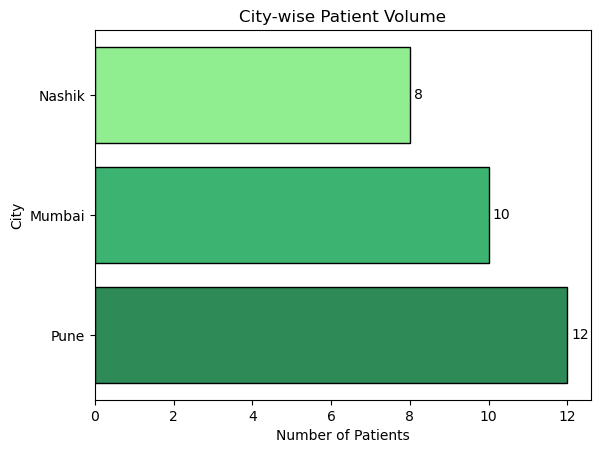

In [231]:
# Create a horizontal bar chart for city-wise patient volume
plt.barh(
    city_patient_count.index,
    city_patient_count.values,
    color=['#2E8B57', '#3CB371', '#90EE90'],   
    height=0.8,                                
    edgecolor='black'
)
# Show the value at the end of each bar
for i, v in enumerate(city_patient_count.values):
    plt.text(v + 0.1, i, str(v), va='center')

# Add a title to the chart
plt.title("City-wise Patient Volume")

# Label the X-axis
plt.xlabel("Number of Patients")

# Label the Y-axis
plt.ylabel("City")

# Display the chart
plt.show()

Analysis: Pune has the highest number of patients (12), followed by Mumbai (10) and Nashik (8).

Business Insights:
1. Highest demand: Pune contributes 40% of all patients (12 out of 30), making it the main demand centre for the hospital group.
2. Lowest demand: Nashik has the fewest patients (8, about 27%), so there may be room to grow services or awareness there.
3. Demand is fairly spread out: The gap between the highest and lowest city is only 4 patients, so no city is far ahead. Pune also has the most Emergency cases (7 of 12), so it may need extra emergency staff and resources.

Task 9 – 30-Day Readmission Analysis

In [232]:
# Count the number of patients for each readmission status
readmission_count = df["Readmission_30_Days"].value_counts()
 
print(readmission_count)

Readmission_30_Days
0    19
1    11
Name: count, dtype: int64


In [233]:
# Rename the readmission status labels
readmission_count.index = readmission_count.index.map({
    0: "Not Readmitted",
    1: "Readmitted"
})
 
print(readmission_count)

Readmission_30_Days
Not Readmitted    19
Readmitted        11
Name: count, dtype: int64


In [234]:
# Calculate the percentage of each readmission category
readmission_percentage = (readmission_count / readmission_count.sum()) * 100
 
print(readmission_percentage)

Readmission_30_Days
Not Readmitted    63.333333
Readmitted        36.666667
Name: count, dtype: float64


In [235]:
readmit = df['Readmission_30_Days'].value_counts().sort_index()
labels = ['Not Readmitted', 'Readmitted']
print(readmit)

Readmission_30_Days
0    19
1    11
Name: count, dtype: int64


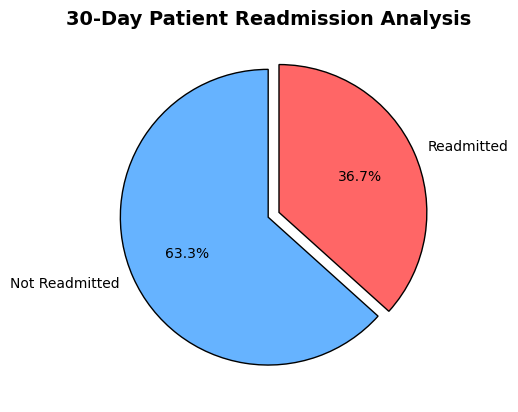

In [236]:
# Create a pie chart showing the readmission percentage
plt.pie(
    readmission_percentage.values,
    labels=readmission_percentage.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=['#66b3ff', '#ff6666'],
    explode=(0, 0.08), wedgeprops={'edgecolor': 'black'},textprops={'fontsize': 10}
)

# Add a title to the chart
plt.title("30-Day Patient Readmission Analysis", fontsize=14, fontweight='bold')

 
plt.show()

Analysis: Out of 30 patients, 11 (36.7%) were readmitted within 30 days, while 19 (63.3%) were not readmitted.

Business Insights:
1. Readmission rate: The 30-day readmission rate is 36.7%, which is very high. Hospitals usually aim for a much lower rate, so this is a concerning level.
2. Readmissions are concentrated: All 11 readmitted patients were Emergency cases from only two departments, Neurology (6 of 6 patients) and Cardiology (5 of 6 patients). No OPD patient and no patient from Pediatrics, Orthopedics or General Medicine was readmitted. 8 of the 11 were ICU patients.
3. Area to improve: Management should improve discharge planning, follow-up visits and post-discharge care for Emergency/ICU patients in Cardiology and Neurology, since this is where readmissions come from.

Task 10 – Age vs Length of Stay

In [237]:
# Display the Age and Length_of_Stay_Days columns
df.head() [["Age", "Length_of_Stay_Days"]]

,Age,Length_of_Stay_Days
0,62,3
1,45,2
2,58,7
3,8,1
4,51,2


In [238]:
corr = df["Age"].corr(df["Length_of_Stay_Days"])
print(f"{corr:.2f}")             # 0.78
print(round(corr, 2))            # 0.78
print(f"Correlation: {corr:.2f}")  # Correlation: 0.78

0.78
0.78
Correlation: 0.78


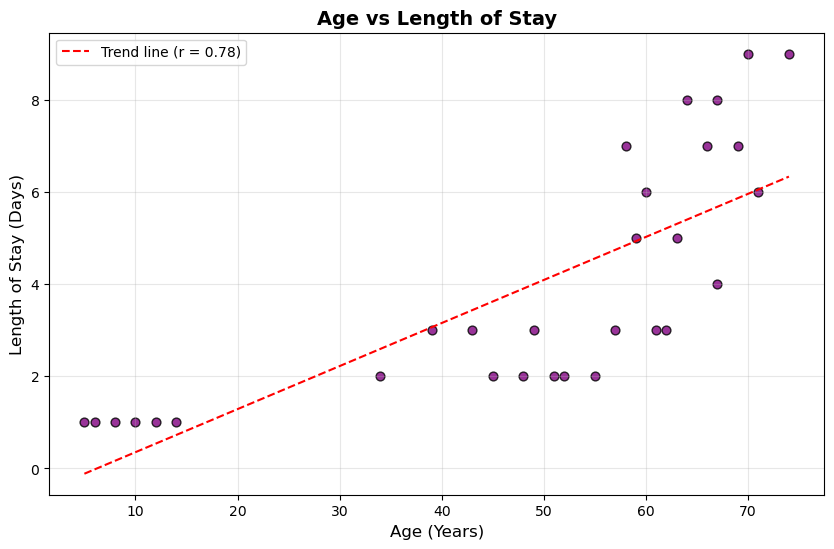

In [239]:
# Create a scatter plot to analyze age versus length of hospital stay
# Chart size (width, height)
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Age"],
    df["Length_of_Stay_Days"],
    color='purple',        # dots color
    s=40,                  # dots size
    edgecolors='black',    # dots border
    alpha=0.8  
)

import numpy as np
m, b = np.polyfit(df["Age"], df["Length_of_Stay_Days"], 1)
x_line = np.linspace(df["Age"].min(), df["Age"].max(), 100)
plt.plot(x_line, m * x_line + b, 'r--', label=f'Trend line (r = {corr:.2f})') 

# Add a title to the chart
plt.title("Age vs Length of Stay", fontsize=14, fontweight='bold')

# Label the X-axis
plt.xlabel("Age (Years)", fontsize=12)

# Label the Y-axis
plt.ylabel("Length of Stay (Days)", fontsize=12)

# Display grid lines
plt.grid(True, alpha=0.3)

# Show the legend
plt.legend()
 
plt.show()

Analysis: There is a strong positive relationship between age and length of stay (correlation ≈ 0.78). Younger patients (under 15 years) stay only 1 day, middle-aged patients stay 2–3 days, and patients aged 58 and above stay 5–9 days.

Business Insights:
1. Older patients stay longer: Patients above 60 years generally stay 6–9 days, while children and younger patients stay 1–3 days. The longest stays (9 days) are patients aged 70 and 74.
2. Unusual cases: Patient 2001 (age 62, Cardiology Emergency) stayed only 3 days, much shorter than other older Emergency patients. Patient 2017 (age 67, Orthopedics) stayed 4 days, also shorter than other patients of similar age. No young patient had a long stay.
3. Planning impact: Older patients, mostly in Cardiology and Neurology ICU, use the most bed days. Management should plan ICU and ward capacity for the elderly and focus on faster recovery and discharge planning for this group.